# 2. Introducción a Pandas

Pandas se construye sobre NumPy y proporciona estructuras de datos de alto nivel: Series (1D) y DataFrame (2D) con índices etiquetados, facilitando el manejo de datos tabulares y de series temporales.

### 2.1 Creación de Series y DataFrames

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Series desde lista
s = pd.Series([1, 3, 5, 7, 9], index=['a', 'b', 'c', 'd', 'e'])
print(s, '\n')
# a    1
# b    3
# c    5
# d    7
# e    9
# dtype: int64

# DataFrame desde diccionario
data = {
    'Nombre': ['Ana', 'Luis', 'Carlos', 'Marta'],
    'Edad': [23, 35, 29, 41],
    'Ciudad': ['Madrid', 'Barcelona', 'Valencia', 'Sevilla']
}
df = pd.DataFrame(data)
print(df, '\n')
#    Nombre  Edad    Ciudad
# 0    Ana    23    Madrid
# 1   Luis    35  Barcelona
# 2  Carlos    29   Valencia
# 3  Marta    41    Sevilla

# Desde lista de listas
df2 = pd.DataFrame([[1, 'A'], [2, 'B'], [3, 'C']], columns=['ID', 'Letra'])
print(df2, '\n')

a    1
b    3
c    5
d    7
e    9
dtype: int64 

   Nombre  Edad     Ciudad
0     Ana    23     Madrid
1    Luis    35  Barcelona
2  Carlos    29   Valencia
3   Marta    41    Sevilla 

   ID Letra
0   1     A
1   2     B
2   3     C 



### 2.2 Lectura y Escritura de Datos


In [3]:
# Leer CSV (se asume que el archivo existe)
# df = pd.read_csv('datos.csv', sep=',', encoding='utf-8', header=0)
# Leer Excel
# df = pd.read_excel('datos.xlsx', sheet_name='Hoja1')
# Leer JSON
# df = pd.read_json('datos.json')

# Escribir a CSV
# df.to_csv('salida.csv', index=False)
# df.to_excel('salida.xlsx', index=False)

### 2.3 Exploración Inicial (EDA Básico)


In [4]:
# Ver primeras y últimas filas
print(df.head(2), '\n')  # primeras 2
print(df.tail(2), '\n')  # últimas 2

# Información general del DataFrame
print(df.info(), '\n')   # muestra tipos, columnas, memoria, etc.

# Estadísticas descriptivas (solo columnas numéricas)
print(df.describe(), '\n')

# Dimensiones
print(df.shape, '\n')    # (4, 3)

# Nombres de columnas
print(df.columns, '\n')

# Tipos de datos
print(df.dtypes, '\n')

# Valores únicos en una columna
print(df['Ciudad'].unique(), '\n')

# Conteo de valores
print(df['Ciudad'].value_counts())

  Nombre  Edad     Ciudad
0    Ana    23     Madrid
1   Luis    35  Barcelona 

   Nombre  Edad    Ciudad
2  Carlos    29  Valencia
3   Marta    41   Sevilla 

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Nombre  4 non-null      str  
 1   Edad    4 non-null      int64
 2   Ciudad  4 non-null      str  
dtypes: int64(1), str(2)
memory usage: 228.0 bytes
None 

            Edad
count   4.000000
mean   32.000000
std     7.745967
min    23.000000
25%    27.500000
50%    32.000000
75%    36.500000
max    41.000000 

(4, 3) 

Index(['Nombre', 'Edad', 'Ciudad'], dtype='str') 

Nombre      str
Edad      int64
Ciudad      str
dtype: object 

<StringArray>
['Madrid', 'Barcelona', 'Valencia', 'Sevilla']
Length: 4, dtype: str 

Ciudad
Madrid       1
Barcelona    1
Valencia     1
Sevilla      1
Name: count, dtype: int64


### 2.4 Selección y Filtrado (Indexación)
Regla de oro: Usa .loc para etiquetas (nombres de filas/columnas) y .iloc para posiciones enteras.

In [5]:
# Selección de columnas (Series)
print(df['Nombre'], '\n')  # o df.Nombre (pero prefiere corchetes para claridad)

# Selección de múltiples columnas (DataFrame)
print(df[['Nombre', 'Edad']], '\n')

# Selección por posición con iloc
print(df.iloc[0], '\n')        # primera fila (todos los atributos)
print(df.iloc[1:3, 0:2], '\n') # filas 1 y 2 (1:3), columnas 0 y 1 (0:2) (Nombre, Edad)

# Selección por etiqueta con loc
print('loc[0]:')
print(df.loc[0], '\n')          # fila con índice 0 (por defecto índice numérico)
# Si tenemos índice personalizado:
df_idx = df.set_index('Nombre')
print(df_idx.loc['Ana'], '\n')  # fila con índice 'Ana'

# Filtrado booleano
mascara = df['Edad'] > 30
print(df[mascara], '\n')        # filas donde Edad > 30

print("Combinar condiciones:")
print(df[(df['Edad'] > 25) & (df['Ciudad'] == 'Madrid')], '\n')

# Selección con .at/.iat (acceso rápido a una sola celda)
print(df.at[0, 'Nombre'], '\n')   # 'Ana'
print(df.iat[1, 1], '\n')         # 35 (fila 1, columna 1)

0       Ana
1      Luis
2    Carlos
3     Marta
Name: Nombre, dtype: str 

   Nombre  Edad
0     Ana    23
1    Luis    35
2  Carlos    29
3   Marta    41 

Nombre       Ana
Edad          23
Ciudad    Madrid
Name: 0, dtype: object 

   Nombre  Edad
1    Luis    35
2  Carlos    29 

loc[0]:
Nombre       Ana
Edad          23
Ciudad    Madrid
Name: 0, dtype: object 

Edad          23
Ciudad    Madrid
Name: Ana, dtype: object 

  Nombre  Edad     Ciudad
1   Luis    35  Barcelona
3  Marta    41    Sevilla 

Combinar condiciones:
Empty DataFrame
Columns: [Nombre, Edad, Ciudad]
Index: [] 

Ana 

35 



### 2.5 Manejo de Datos Faltantes (NaN)


In [6]:
# Detectar valores nulos
print(df.isnull(), '\n')          # DataFrame de booleanos
print(df.isnull().sum(), '\n')    # conteo por columna

   Nombre   Edad  Ciudad
0   False  False   False
1   False  False   False
2   False  False   False
3   False  False   False 

Nombre    0
Edad      0
Ciudad    0
dtype: int64 



In [7]:

# Eliminar filas con cualquier NaN
df_dropna = df.dropna()  # axis=0 para filas, axis=1 para columnas

# Eliminar columnas con todos NaN
df_dropna_col = df.dropna(axis=1, how='all')

# Rellenar NaN con un valor
df_fill = df.fillna(0)  # o con media: df.fillna(df.mean())

# Rellenar hacia adelante/atrás (antes de pandas 2.0)
# df_ffill = df.fillna(method='ffill')  # forward fill
# df_bfill = df.fillna(method='bfill')  # backward fill

# Rellenar hacia adelante (forward fill) - propaga el último valor válido
df_ffill = df.ffill()

# Rellenar hacia atrás (backward fill) - propaga el siguiente valor válido
df_bfill = df.bfill()

# Interpolación (para series temporales)
# df.interpolate(method='linear')

### 2.6 Manipulación de Datos: Añadir/Eliminar Columnas, Renombrar

In [8]:
# Añadir columna nueva
df['Edad_cuadrado'] = df['Edad'] ** 2
print(df, '\n')

# Usar assign (más funcional)
df = df.assign(Edad_cubo=lambda x: x['Edad'] ** 3)

# Eliminar columna
df_clean = df.drop('Edad_cuadrado', axis=1)  # axis=1 para columna
# También inplace=True (pero evítalo, mejor asigna)

# Renombrar columnas
df_renamed = df.rename(columns={'Edad': 'Age', 'Ciudad': 'City'})
print(df_renamed.columns, '\n')

   Nombre  Edad     Ciudad  Edad_cuadrado
0     Ana    23     Madrid            529
1    Luis    35  Barcelona           1225
2  Carlos    29   Valencia            841
3   Marta    41    Sevilla           1681 

Index(['Nombre', 'Age', 'City', 'Edad_cuadrado', 'Edad_cubo'], dtype='str') 



### 2.7 Aplicar Funciones a Datos


In [9]:
# apply: aplicar función a filas o columnas
# Calcular el rango de edad (max-min) por fila (no tiene sentido aquí)
df['Rango'] = df[['Edad']].apply(lambda x: x.max() - x.min(), axis=1)

df.head()

,Nombre,Edad,Ciudad,Edad_cuadrado,Edad_cubo,Rango
0,Ana,23,Madrid,529,12167,0
1,Luis,35,Barcelona,1225,42875,0
2,Carlos,29,Valencia,841,24389,0
3,Marta,41,Sevilla,1681,68921,0


In [10]:
# Mejor ejemplo: aplicar a columna
df['Edad_cat'] = df['Edad'].apply(lambda x: 'Joven' if x < 30 else 'Adulto')

df.head()

,Nombre,Edad,Ciudad,Edad_cuadrado,Edad_cubo,Rango,Edad_cat
0,Ana,23,Madrid,529,12167,0,Joven
1,Luis,35,Barcelona,1225,42875,0,Adulto
2,Carlos,29,Valencia,841,24389,0,Joven
3,Marta,41,Sevilla,1681,68921,0,Adulto


In [11]:
# map: reemplazar valores en una Series
df['Ciudad_cod'] = df['Ciudad'].map({'Madrid': 'MAD', 'Barcelona': 'BCN', 'Valencia': 'VAL', 'Sevilla': 'SEV'})

df['Ciudad_cod']

0    MAD
1    BCN
2    VAL
3    SEV
Name: Ciudad_cod, dtype: str

In [12]:
# applymap: aplicar función a cada elemento del DataFrame
# df_num = df.select_dtypes(include=[np.number])  # solo numéricas
# df_num_log = df_num.applymap(lambda x: np.log(x) if x > 0 else 0)


# applymap ha sido reemplazado por map en DataFrames (pandas >= 2.1.0)
df_num = df.select_dtypes(include=[np.number])  # solo columnas numéricas
df_num_log = df_num.map(lambda x: np.log(x) if x > 0 else 0)

print(df_num, '\n\n\n')
print(df_num_log, '\n')

   Edad  Edad_cuadrado  Edad_cubo  Rango
0    23            529      12167      0
1    35           1225      42875      0
2    29            841      24389      0
3    41           1681      68921      0 



       Edad  Edad_cuadrado  Edad_cubo  Rango
0  3.135494       6.270988   9.406483      0
1  3.555348       7.110696  10.666044      0
2  3.367296       6.734592  10.101887      0
3  3.713572       7.427144  11.140716      0 



### 2.8 Agrupación (GroupBy)


In [13]:
# Agrupar por una columna y calcular agregaciones
grouped = df.groupby('Ciudad')
grouped['Edad'].mean()  # edad media por ciudad


Ciudad
Barcelona    35.0
Madrid       23.0
Sevilla      41.0
Valencia     29.0
Name: Edad, dtype: float64

In [14]:
df.columns

Index(['Nombre', 'Edad', 'Ciudad', 'Edad_cuadrado', 'Edad_cubo', 'Rango',
       'Edad_cat', 'Ciudad_cod'],
      dtype='str')

In [27]:
# Múltiples agregaciones
agg_dict = {
    'Edad': ['mean', 'max', 'min'],
    'Edad_cubo': 'sum'
}
grouped.agg(agg_dict)

Edad         Edad_cubo
           mean max min       sum
Ciudad                           
Barcelona  35.0  35  35     42875
Madrid     23.0  23  23     12167
Sevilla    41.0  41  41     68921
Valencia   29.0  29  29     24389

In [28]:
# Transform: aplicar función que devuelve el mismo tamaño
df['Edad_centrada'] = df.groupby('Ciudad')['Edad'].transform(lambda x: x - x.mean())

df.head()

,Nombre,Edad,Ciudad,Edad_cuadrado,Edad_cubo,Rango,Edad_cat,Ciudad_cod,Edad_centrada,Ciudad_encoded,Edad_estandar,Edad_minmax,Edad_robust,Edad_Interaccion,Edad_bin
0,Ana,23,Madrid,529,12167,0,Joven,MAD,0.0,1,-1.341641,0.000000,-1.000000,279841,Joven
1,Luis,35,Barcelona,1225,42875,0,Adulto,BCN,0.0,0,0.447214,0.666667,0.333333,1500625,Adulto
2,Carlos,29,Valencia,841,24389,0,Joven,VAL,0.0,3,-0.447214,0.333333,-0.333333,707281,Joven
3,Marta,41,Sevilla,1681,68921,0,Adulto,SEV,0.0,2,1.341641,1.000000,1.000000,2825761,Senior


In [30]:
# Filter: filtrar grupos según condición
# Solo ciudades con edad media > 30
df_filtrado = df.groupby('Ciudad').filter(lambda g: g['Edad'].mean() > 30)
df_filtrado

,Nombre,Edad,Ciudad,Edad_cuadrado,Edad_cubo,Rango,Edad_cat,Ciudad_cod,Edad_centrada,Ciudad_encoded,Edad_estandar,Edad_minmax,Edad_robust,Edad_Interaccion,Edad_bin
1,Luis,35,Barcelona,1225,42875,0,Adulto,BCN,0.0,0,0.447214,0.666667,0.333333,1500625,Adulto
3,Marta,41,Sevilla,1681,68921,0,Adulto,SEV,0.0,2,1.341641,1.000000,1.000000,2825761,Senior


### 2.9 Combinación de DataFrames: Merge, Concat, Join


In [16]:
df1 = pd.DataFrame({'ID': [1, 2, 3], 'Nombre': ['Ana', 'Luis', 'Carlos']})
df2 = pd.DataFrame({'ID': [1, 2, 4], 'Edad': [23, 35, 41]})

# Merge (similar a SQL JOIN)
merged = pd.merge(df1, df2, on='ID', how='inner')  # inner, left, right, outer
print(merged, '\n')

# Concat (apilar)
df3 = pd.DataFrame({'ID': [5, 6], 'Nombre': ['Marta', 'Pedro']})
concat = pd.concat([df1, df3], ignore_index=True)
print(concat, '\n')

# Join (usando índice)
df1_idx = df1.set_index('ID')
df2_idx = df2.set_index('ID')
joined = df1_idx.join(df2_idx, how='inner')

   ID Nombre  Edad
0   1    Ana    23
1   2   Luis    35 

   ID  Nombre
0   1     Ana
1   2    Luis
2   3  Carlos
3   5   Marta
4   6   Pedro 



### 2.10 Tablas Cruzadas y Pivot

In [17]:
# Pivot table: resumir datos
data = {
    'Fecha': ['2023-01-01', '2023-01-01', '2023-01-02', '2023-01-02'],
    'Producto': ['A', 'B', 'A', 'B'],
    'Ventas': [100, 150, 200, 50]
}
df_ventas = pd.DataFrame(data)

pivot = df_ventas.pivot_table(index='Fecha', columns='Producto', values='Ventas', aggfunc='sum')
print(pivot, '\n')
# Producto    A    B
# Fecha            
# 2023-01-01 100  150
# 2023-01-02 200   50

# Crosstab (frecuencias)
pd.crosstab(df['Ciudad'], df['Edad_cat'])

Producto      A    B
Fecha               
2023-01-01  100  150
2023-01-02  200   50 



Edad_cat,Adulto,Joven
Ciudad,,
Barcelona,1,0
Madrid,0,1
Sevilla,1,0
Valencia,0,1


### 2.11 Series Temporales


In [18]:
# Crear un índice de fechas
fechas = pd.date_range('2023-01-01', periods=10, freq='D')
ts = pd.Series(np.random.randn(10), index=fechas)
print(ts, '\n')

# Resample: cambiar frecuencia
ts_resampled = ts.resample('3D').mean()  # cada 3 días, media

# Ventanas móviles
ts_rolling = ts.rolling(window=3).mean()  # media móvil de 3 días

# Shift (desplazar)
ts_shifted = ts.shift(1)  # datos del día anterior

# Diferencia
ts_diff = ts.diff()  # diferencia entre días consecutivos

2023-01-01    0.173598
2023-01-02   -0.093074
2023-01-03    1.761078
2023-01-04    0.127061
2023-01-05    0.684873
2023-01-06    0.153083
2023-01-07   -0.554472
2023-01-08   -0.408763
2023-01-09    0.563587
2023-01-10    0.223428
Freq: D, dtype: float64 



### 2.12 Datos Categóricos


In [19]:
df['Ciudad'] = df['Ciudad'].astype('category')
print(df['Ciudad'].cat.codes)  # códigos numéricos
print(df['Ciudad'].cat.categories)  # categorías

0    1
1    0
2    3
3    2
dtype: int8
Index(['Barcelona', 'Madrid', 'Sevilla', 'Valencia'], dtype='str')


-------------


## 3. Exploratory Data Analysis (EDA) Avanzado
EDA es el proceso de conocer los datos, detectar anomalías, patrones y preparar el terreno para modelado.

### 3.1 Análisis Univariante


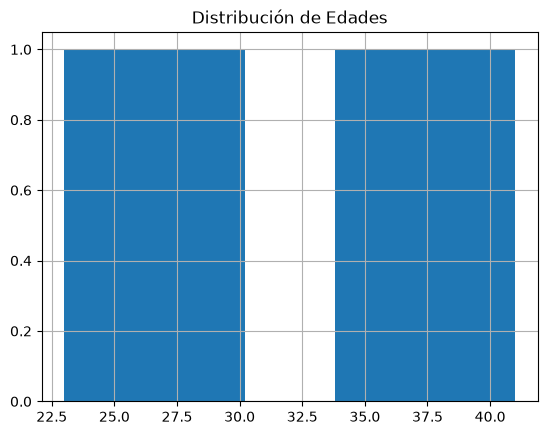

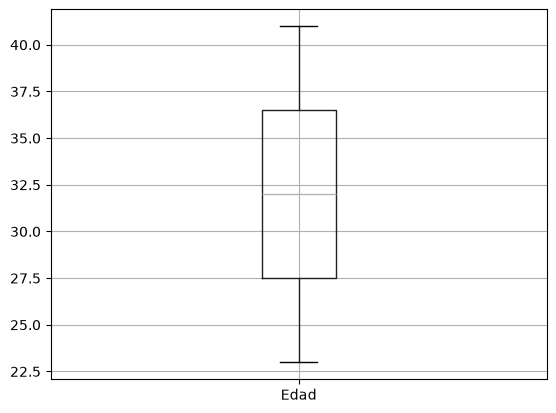

count     4.000000
mean     32.000000
std       7.745967
min      23.000000
1%       23.180000
5%       23.900000
95%      40.100000
99%      40.820000
max      41.000000
Name: Edad, dtype: float64


In [20]:
df['Edad'].hist(bins=5)
plt.title('Distribución de Edades')
plt.show()

# Boxplot para detectar outliers
df.boxplot(column='Edad')
plt.show()

# Estadísticas detalladas con .describe() incluyendo percentiles
print(df['Edad'].describe(percentiles=[0.01, 0.05, 0.95, 0.99]))

### 3.2 Análisis Bivariante y Multivariante


                   Edad  Edad_cuadrado  Edad_cubo  Rango  Edad_centrada
Edad           1.000000       0.996503   0.986831    NaN            NaN
Edad_cuadrado  0.996503       1.000000   0.996884    NaN            NaN
Edad_cubo      0.986831       0.996884   1.000000    NaN            NaN
Rango               NaN            NaN        NaN    NaN            NaN
Edad_centrada       NaN            NaN        NaN    NaN            NaN


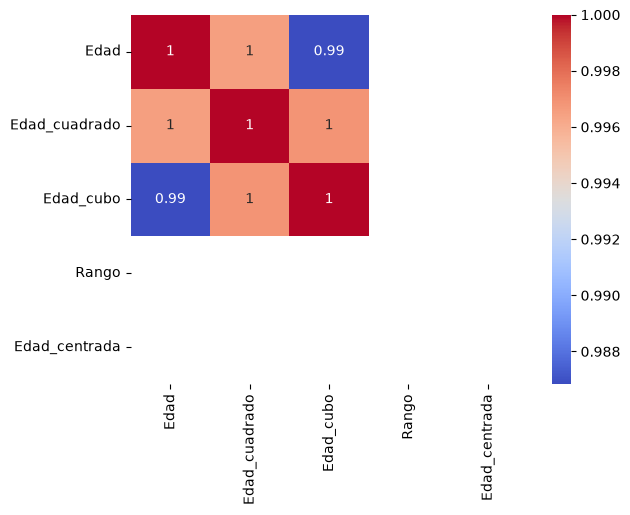

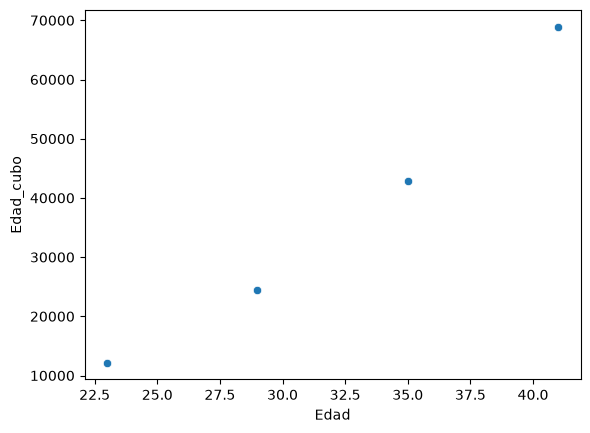

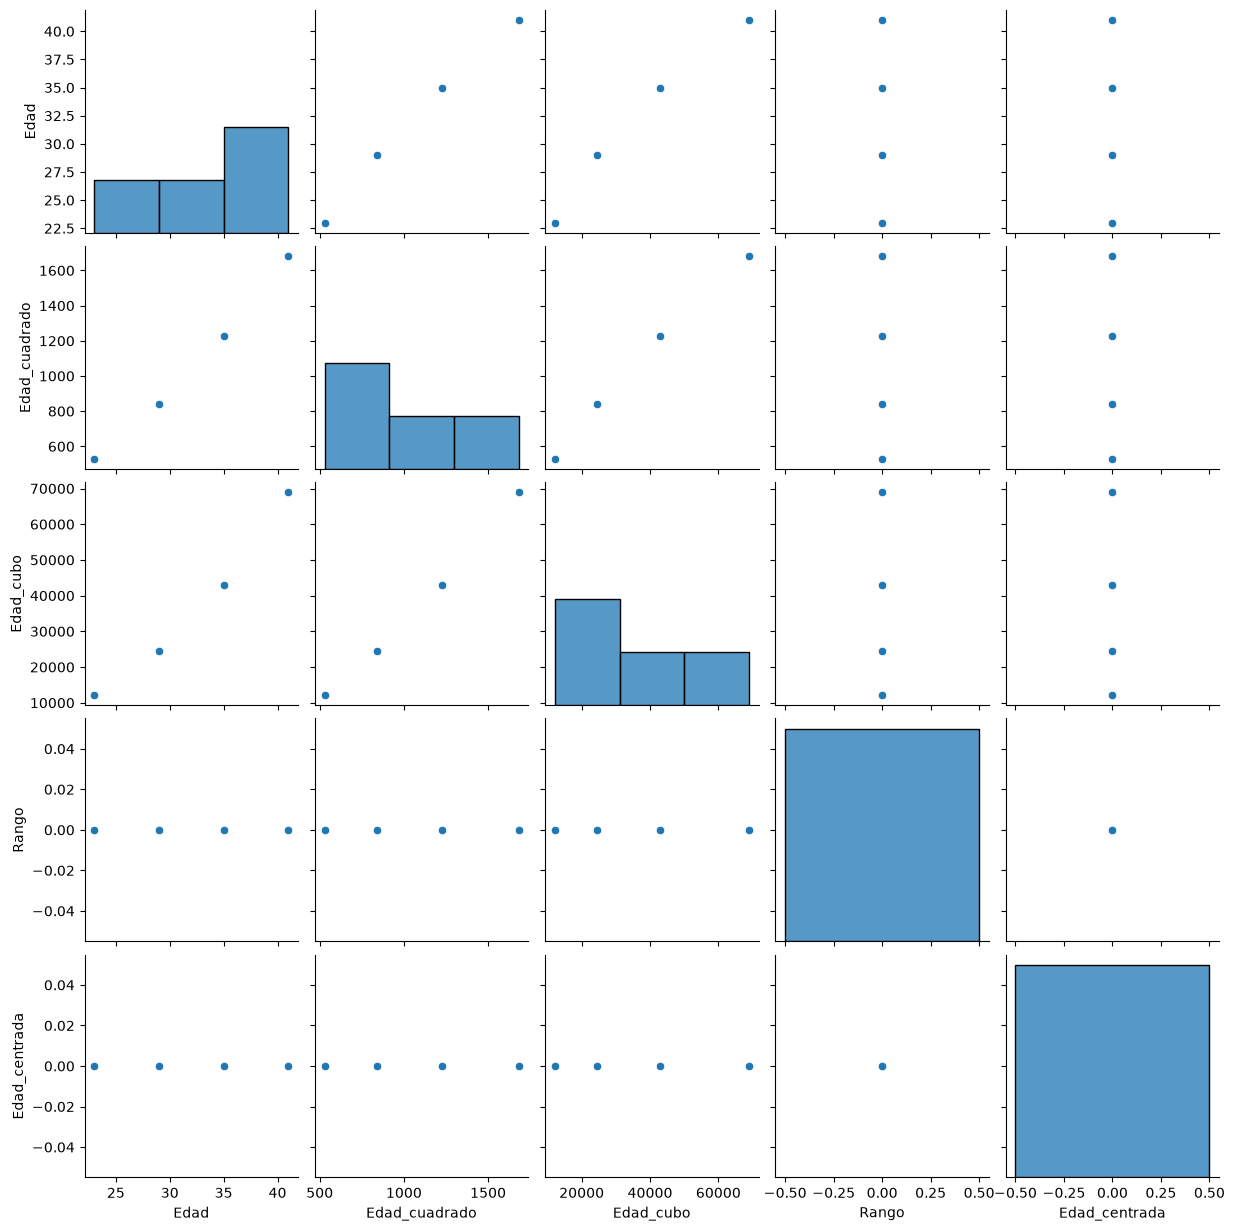

In [21]:
# Correlación entre variables numéricas
corr_matrix = df.select_dtypes(include=[np.number]).corr()
print(corr_matrix)

# Heatmap con seaborn (mejor visual)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()

# Scatter plot
sns.scatterplot(x='Edad', y='Edad_cubo', data=df)
plt.show()

# Pairplot
sns.pairplot(df.select_dtypes(include=[np.number]))
plt.show()

### 3.3 Detección de Outliers


In [22]:
# Método IQR
Q1 = df['Edad'].quantile(0.25)
Q3 = df['Edad'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['Edad'] < lower_bound) | (df['Edad'] > upper_bound)]
print(outliers)

# Z-score (suponiendo distribución normal)
from scipy import stats
z_scores = np.abs(stats.zscore(df['Edad']))
outliers_z = df[z_scores > 3]

Empty DataFrame
Columns: [Nombre, Edad, Ciudad, Edad_cuadrado, Edad_cubo, Rango, Edad_cat, Ciudad_cod, Edad_centrada]
Index: []


### 3.4 Visualización de Datos Faltantes


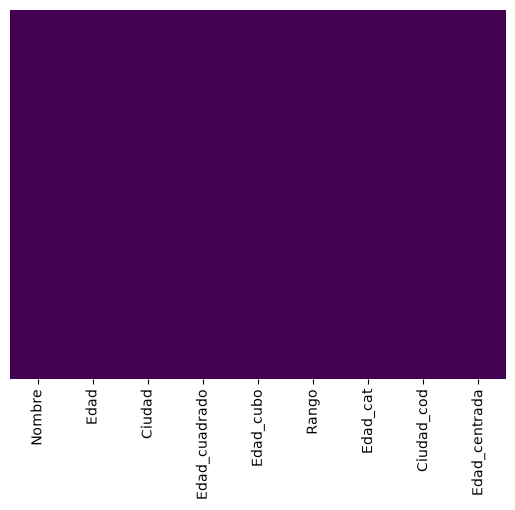

No hay valores nulos en el DataFrame.


In [23]:
# Mapa de calor de nulos
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.show()

# Conteo de nulos
missing = df.isnull().sum()
missing = missing[missing > 0]

if not missing.empty:
    missing.sort_values(inplace=True)
    missing.plot.bar()
    plt.title('Número de valores nulos por columna')
    plt.ylabel('Cantidad de nulos')
    plt.show()
else:
    print("No hay valores nulos en el DataFrame.")

----------

## 4. Data Mining y Preprocesamiento
Aquí se preparan los datos para algoritmos de machine learning.

### 4.1 Codificación de Variables Categóricas

In [24]:
# One-Hot Encoding (crea columnas binarias)
df_ohe = pd.get_dummies(df, columns=['Ciudad'], prefix='Ciudad')
print(df_ohe)

# Label Encoding (asigna números)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Ciudad_encoded'] = le.fit_transform(df['Ciudad'])

# Para categorías con orden (OrdinalEncoder)

   Nombre  Edad  Edad_cuadrado  Edad_cubo  Rango Edad_cat Ciudad_cod  \
0     Ana    23            529      12167      0    Joven        MAD   
1    Luis    35           1225      42875      0   Adulto        BCN   
2  Carlos    29            841      24389      0    Joven        VAL   
3   Marta    41           1681      68921      0   Adulto        SEV   

   Edad_centrada  Ciudad_Barcelona  Ciudad_Madrid  Ciudad_Sevilla  \
0            0.0             False           True           False   
1            0.0              True          False           False   
2            0.0             False          False           False   
3            0.0             False          False            True   

   Ciudad_Valencia  
0            False  
1            False  
2             True  
3            False  


### 4.2 Escalado y Normalización


In [25]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Estandarización (media=0, std=1)
scaler = StandardScaler()
df['Edad_estandar'] = scaler.fit_transform(df[['Edad']])

# Min-Max (0 a 1)
minmax = MinMaxScaler()
df['Edad_minmax'] = minmax.fit_transform(df[['Edad']])

# Robust (usa mediana y IQR, menos sensible a outliers)
robust = RobustScaler()
df['Edad_robust'] = robust.fit_transform(df[['Edad']])

### 4.3 Creación de Nuevas Características (Feature Engineering)


In [26]:
# Ejemplo: interacciones, polinomios, binning
df['Edad_Interaccion'] = df['Edad'] * df['Edad_cubo']  # sin sentido, solo ejemplo
# Binning
bins = [0, 30, 40, 100]
labels = ['Joven', 'Adulto', 'Senior']
df['Edad_bin'] = pd.cut(df['Edad'], bins=bins, labels=labels)
print(df['Edad_bin'])

# Extraer información de fechas
df['Fecha'] = pd.to_datetime(df['Fecha'])  # si existe
# df['Dia_semana'] = df['Fecha'].dt.dayofweek
# df['Mes'] = df['Fecha'].dt.month

0     Joven
1    Adulto
2     Joven
3    Senior
Name: Edad_bin, dtype: category
Categories (3, str): ['Joven' < 'Adulto' < 'Senior']


KeyError: 'Fecha'

### 4.4 Manejo de Datos Desbalanceados (opcional)


In [ ]:
# Técnicas como SMOTE (requiere imbalanced-learn)
# from imblearn.over_sampling import SMOTE
# X_resampled, y_resampled = SMOTE().fit_resample(X, y)

### 4.5 Pipelines de Preprocesamiento (scikit-learn)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # ← ¡Importante!
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# Definir transformadores para columnas numéricas y categóricas
numeric_features = ['Edad']
categorical_features = ['Ciudad']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))  # sparse_output=False devuelve array denso
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Ahora puedes usar este preprocesador en un Pipeline con un modelo
# Ejemplo de uso:
# from sklearn.linear_model import LinearRegression
# model = Pipeline(steps=[('preprocessor', preprocessor),
#                         ('regressor', LinearRegression())])

### 4.6 Ejemplo de Modelado Simple (Regresión Lineal)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Supongamos que queremos predecir 'Edad_cubo' usando 'Edad'
X = df[['Edad']]  # características
y = df['Edad_cubo']  # objetivo

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))

RMSE: 5214.8571428571595


## 5. Buenas Prácticas y Consejos

1. **Usa `.loc` y `.iloc` explícitamente** en lugar de encadenar (e.g., `df[df['A'] > 0]['B']`). Prefiere `df.loc[df['A'] > 0, 'B']`.

2. **Evita `inplace=True`**: es mejor asignar a una nueva variable para mantener trazabilidad y evitar efectos laterales.

3. **Copia explícita** cuando modifiques una vista: `df_copy = df.copy()`.

4. **Optimiza memoria** convirtiendo tipos: `df['col'] = df['col'].astype('int32')` o usar `pd.to_numeric` con `downcast`.

5. **Aprovecha la vectorización**: evita bucles `for`; usa operaciones de Pandas/NumPy.

6. **Usa `pipe`** para encadenar transformaciones complejas.

7. **Documenta tu código** con comentarios.

8. **Mantén un índice significativo** (por ejemplo, fechas) cuando trabajes con series temporales.

9. **Usa `.query()`** para filtros complejos: `df.query('Edad > 30 and Ciudad == "Madrid"')`.

10. **Guarda versiones intermedias** de datos procesados para no repetir cálculos.
